In [1]:
# ==========================================================================
# TAREA 1: INGESTA, DIAGNÓSTICO Y SUSTITUCIÓN DE CENTINELAS
# ==========================================================================
import pandas as pd
import numpy as np
# 1. Cargar o definir el dataset
data = {
    'ID_Registro': ['REG-001', 'REG-002', 'REG-003', 'REG-004', 'REG-005',
                    'REG-006', 'REG-007', 'REG-008', 'REG-009', 'REG-010', 'REG-010'],
    'Timestamp': ['2026-10-01 08:00:00', '2026-10-01 09:00:00', '2026-10-01 10:00:00',
                  '2026-10-01 11:00:00', '2026-10-01 12:00:00', '2026-10-01 13:00:00',
                  '2026-10-01 14:00:00', '2026-10-01 15:00:00', '2026-10-01 16:00:00',
                  '2026-10-01 17:00:00', '2026-10-01 17:00:00'],
    'Zona_Estacion': ['Centro_Historico', 'centro_historico', 'CENTRO_HISTORICO',
                      'Zona_Oriente', 'Zona_Oriente', 'zona_oriente', 'Zona_Sur',
                      'Zona_Sur', 'Zona_Sur', 'Zona_Sur', 'Zona_Sur'],
    'Concentracion_PM25': [35.4, 42.1, -999.0, 120.5, np.nan, 310.0, 18.2, 20.1, 19.5, 19.5, 19.5],
    'Nivel_NO2': [42.1, 48.5, 51.0, 89.2, 82.0, 195.0, 22.4, -999.0, 25.1, 25.1, 25.1],
    'Indice_Trafico_Vehicular': [85.0, 92.5, 88.0, 98.0, 91.2, 15.0, 45.0, 42.1, np.nan, 41.0, 41.0],
    'Estado_Sensor': ['Normal', 'Normal', 'Alerta', 'Alerta', 'Normal', 'Falla', 'Normal',
                      'Normal', 'Normal', 'Normal', 'Normal']
}
df_raw = pd.DataFrame(data)
display(df_raw.head())
print("Filas y columnas iniciales:", df_raw.shape)
# Identificar columnas numéricas
columnas_numericas = df_raw.select_dtypes(
    include="number"
).columns
# Contar NaN explícitos
print("VALORES NaN POR COLUMNA")
display(df_raw[columnas_numericas].isna().sum())
# Contar los valores centinela
print("VALORES -999.0 POR COLUMNA")
display(df_raw[columnas_numericas].eq(-999.0).sum())
# Contar filas duplicadas
print("Filas totalmente duplicadas:", df_raw.duplicated().sum())
# Crear una copia para conservar los datos originales
df_raw = df_raw.copy()
# Reemplazar -999.0 por NaN
df_raw[columnas_numericas] = df_raw[
    columnas_numericas
].replace(-999.0, np.nan)
# Eliminar filas totalmente duplicadas
df_raw = df_raw.drop_duplicates().reset_index(drop=True)
print("DATAFRAME DESPUÉS DE LA LIMPIEZA INICIAL")
display(df_raw)
print("Dimensiones finales:", df_raw.shape)
print("\nValores faltantes por columna:")
display(df_raw.isna().sum())

,ID_Registro,Timestamp,Zona_Estacion,Concentracion_PM25,Nivel_NO2,Indice_Trafico_Vehicular,Estado_Sensor
0,REG-001,2026-10-01 08:00:00,Centro_Historico,35.4,42.1,85.0,Normal
1,REG-002,2026-10-01 09:00:00,centro_historico,42.1,48.5,92.5,Normal
2,REG-003,2026-10-01 10:00:00,CENTRO_HISTORICO,-999.0,51.0,88.0,Alerta
3,REG-004,2026-10-01 11:00:00,Zona_Oriente,120.5,89.2,98.0,Alerta
4,REG-005,2026-10-01 12:00:00,Zona_Oriente,NaN,82.0,91.2,Normal


Filas y columnas iniciales: (11, 7)
VALORES NaN POR COLUMNA


Concentracion_PM25          1
Nivel_NO2                   0
Indice_Trafico_Vehicular    1
dtype: int64

VALORES -999.0 POR COLUMNA


Concentracion_PM25          1
Nivel_NO2                   1
Indice_Trafico_Vehicular    0
dtype: int64

Filas totalmente duplicadas: 1
DATAFRAME DESPUÉS DE LA LIMPIEZA INICIAL


,ID_Registro,Timestamp,Zona_Estacion,Concentracion_PM25,Nivel_NO2,Indice_Trafico_Vehicular,Estado_Sensor
0,REG-001,2026-10-01 08:00:00,Centro_Historico,35.4,42.1,85.0,Normal
1,REG-002,2026-10-01 09:00:00,centro_historico,42.1,48.5,92.5,Normal
2,REG-003,2026-10-01 10:00:00,CENTRO_HISTORICO,NaN,51.0,88.0,Alerta
3,REG-004,2026-10-01 11:00:00,Zona_Oriente,120.5,89.2,98.0,Alerta
4,REG-005,2026-10-01 12:00:00,Zona_Oriente,NaN,82.0,91.2,Normal
5,REG-006,2026-10-01 13:00:00,zona_oriente,310.0,195.0,15.0,Falla
6,REG-007,2026-10-01 14:00:00,Zona_Sur,18.2,22.4,45.0,Normal
7,REG-008,2026-10-01 15:00:00,Zona_Sur,20.1,NaN,42.1,Normal
8,REG-009,2026-10-01 16:00:00,Zona_Sur,19.5,25.1,NaN,Normal
9,REG-010,2026-10-01 17:00:00,Zona_Sur,19.5,25.1,41.0,Normal


Dimensiones finales: (10, 7)

Valores faltantes por columna:


ID_Registro                 0
Timestamp                   0
Zona_Estacion               0
Concentracion_PM25          2
Nivel_NO2                   1
Indice_Trafico_Vehicular    1
Estado_Sensor               0
dtype: int64

In [2]:
# ==========================================================================
# TAREA 2: PIPELINE DE LIMPIEZA, FEATURE ENGINEERING E IMPUTACIÓN
# ==========================================================================
from sklearn.impute import KNNImputer
df_clean = df_raw.copy()
# 1. Homogeneizar las zonas
mapa_zonas = {
    "centro_historico": "Centro_Historico",
    "zona_oriente": "Zona_Oriente",
    "zona_sur": "Zona_Sur"
}
df_clean["Zona_Estacion"] = (
    df_clean["Zona_Estacion"]
    .str.strip()
    .str.lower()
    .map(mapa_zonas))
# 2. Convertir Timestamp y obtener Hora_Dia
df_clean["Timestamp"] = pd.to_datetime(
    df_clean["Timestamp"], errors="coerce")
df_clean["Hora_Dia"] = df_clean["Timestamp"].dt.hour
# 3. Detectar valores atípicos mediante IQR
columna = "Concentracion_PM25"
q1 = df_clean[columna].quantile(0.25)
q3 = df_clean[columna].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
outliers = ((df_clean[columna] < limite_inferior) |
    (df_clean[columna] > limite_superior))
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Cantidad de outliers:", int(outliers.sum()))
# Mostrar los registros identificados antes de reemplazarlos
display(df_clean.loc[outliers, [
    "ID_Registro", "Concentracion_PM25", "Estado_Sensor"]])
# Sustituir los valores atípicos por NaN
df_clean.loc[outliers, columna] = np.nan
# 4. Imputar las tres variables numéricas
columnas_imputar = ["Concentracion_PM25",
    "Nivel_NO2",
    "Indice_Trafico_Vehicular"]
imputer = KNNImputer(n_neighbors=2)
df_clean[columnas_imputar] = imputer.fit_transform(
    df_clean[columnas_imputar])
# 5. Verificar los resultados
print("DATAFRAME LIMPIO E IMPUTADO")
display(df_clean)
print("Valores faltantes por columna:")
display(df_clean.isna().sum())
print("Zonas normalizadas:")
print(df_clean["Zona_Estacion"].unique())


Q1: 19.5
Q3: 61.7
IQR: 42.2
Límite inferior: -43.800000000000004
Límite superior: 125.0
Cantidad de outliers: 1


,ID_Registro,Concentracion_PM25,Estado_Sensor
5,REG-006,310.0,Falla


DATAFRAME LIMPIO E IMPUTADO


,ID_Registro,Timestamp,Zona_Estacion,Concentracion_PM25,Nivel_NO2,Indice_Trafico_Vehicular,Estado_Sensor,Hora_Dia
0,REG-001,2026-10-01 08:00:00,Centro_Historico,35.40,42.1,85.00,Normal,8
1,REG-002,2026-10-01 09:00:00,Centro_Historico,42.10,48.5,92.50,Normal,9
2,REG-003,2026-10-01 10:00:00,Centro_Historico,38.75,51.0,88.00,Alerta,10
3,REG-004,2026-10-01 11:00:00,Zona_Oriente,120.50,89.2,98.00,Alerta,11
4,REG-005,2026-10-01 12:00:00,Zona_Oriente,81.30,82.0,91.20,Normal,12
5,REG-006,2026-10-01 13:00:00,Zona_Oriente,70.30,195.0,15.00,Falla,13
6,REG-007,2026-10-01 14:00:00,Zona_Sur,18.20,22.4,45.00,Normal,14
7,REG-008,2026-10-01 15:00:00,Zona_Sur,20.10,25.1,42.10,Normal,15
8,REG-009,2026-10-01 16:00:00,Zona_Sur,19.50,25.1,41.55,Normal,16
9,REG-010,2026-10-01 17:00:00,Zona_Sur,19.50,25.1,41.00,Normal,17


Valores faltantes por columna:


ID_Registro                 0
Timestamp                   0
Zona_Estacion               0
Concentracion_PM25          0
Nivel_NO2                   0
Indice_Trafico_Vehicular    0
Estado_Sensor               0
Hora_Dia                    0
dtype: int64

Zonas normalizadas:
<ArrowStringArray>
['Centro_Historico', 'Zona_Oriente', 'Zona_Sur']
Length: 3, dtype: str


ESTADÍSTICAS DESCRIPTIVAS DE PM2.5


,Valor
Media,46.5650
Mediana,37.0750
Desviación estándar,34.0129
Skewness (asimetría),1.3288
Kurtosis (curtosis),1.1865


MATRIZ DE CORRELACIÓN DE PEARSON


,Concentracion_PM25,Nivel_NO2,Indice_Trafico_Vehicular,Hora_Dia
Concentracion_PM25,1.000,0.638,0.449,-0.384
Nivel_NO2,0.638,1.000,-0.203,-0.185
Indice_Trafico_Vehicular,0.449,-0.203,1.000,-0.749
Hora_Dia,-0.384,-0.185,-0.749,1.000


MATRIZ DE CORRELACIÓN DE SPEARMAN


,Concentracion_PM25,Nivel_NO2,Indice_Trafico_Vehicular,Hora_Dia
Concentracion_PM25,1.000,0.942,0.559,-0.559
Nivel_NO2,0.942,1.000,0.325,-0.497
Indice_Trafico_Vehicular,0.559,0.325,1.000,-0.697
Hora_Dia,-0.559,-0.497,-0.697,1.000


PEARSON
No hay pares con |r| >= 0.85.

SPEARMAN


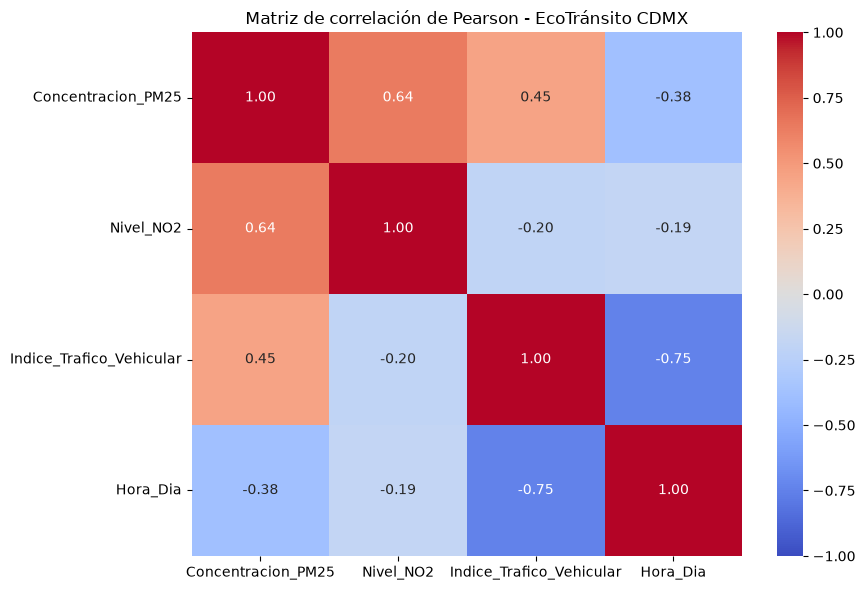

In [3]:
# ==========================================================================
# TAREA 3: EDA Y ANÁLISIS DE CORRELACIÓN
# ==========================================================================
# 1. Estadísticas de forma para Concentracion_PM25
pm25 = df_clean["Concentracion_PM25"]
resultados = pd.Series({
    "Media": pm25.mean(),
    "Mediana": pm25.median(),
    "Desviación estándar": pm25.std(),
    "Skewness (asimetría)": pm25.skew(),
    "Kurtosis (curtosis)": pm25.kurt()})
print("ESTADÍSTICAS DESCRIPTIVAS DE PM2.5")
display(resultados.to_frame(name="Valor").round(4))
# 2. Matrices de correlación Pearson y Spearman
df_numerico = df_clean.select_dtypes(include=np.number)
# Correlación de Pearson
corr_pearson = df_numerico.corr(method="pearson")
print("MATRIZ DE CORRELACIÓN DE PEARSON")
display(corr_pearson.round(3))
# Correlación de Spearman
corr_spearman = df_numerico.corr(method="spearman")
print("MATRIZ DE CORRELACIÓN DE SPEARMAN")
display(corr_spearman.round(3))
# Buscar pares con correlación absoluta >= 0.85
def buscar_correlaciones_fuertes(matriz, umbral=0.85):
    mascara = np.triu(
        np.ones(matriz.shape, dtype=bool), k=1)
    pares = matriz.where(mascara).stack()
    fuertes = pares[pares.abs() >= umbral]
    if fuertes.empty:
        print(f"No hay pares con |r| >= {umbral}.")
    else:
        for (var1, var2), valor in fuertes.items():
            print(f"{var1} y {var2}: {valor:.3f}")
print("PEARSON")
buscar_correlaciones_fuertes(corr_pearson)
print("\nSPEARMAN")

import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 6))
sns.heatmap(corr_pearson,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0)
plt.title("Matriz de correlación de Pearson - EcoTránsito CDMX")
plt.tight_layout()
plt.show()